<a href="https://colab.research.google.com/github/guivilarim/RNA-e-Deep-Learning---CESAR-School-2026.01-A/blob/main/Atividade%202/atividade_2_Guilherme_Vilarim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade 2 — Regressão linear com várias variáveis: preço de casas na Califórnia

Nessa atividade vou usar o mesmo pipeline do notebook 2.6 (`nn.Linear`, `nn.MSELoss`, `optim.SGD`, treino × validação), mas agora com 8 variáveis de entrada em vez de 1. O objetivo é prever o preço mediano das casas de cada quarteirão da Califórnia.

O modelo agora é:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8$$

ou seja, `nn.Linear(8, 1)`: 8 pesos + 1 bias = 9 parâmetros.

## Importação das bibliotecas

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Leitura

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # y em centenas de milhares de dólares

print('X:', X.shape, ' y:', y.shape)
X.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### O que cada variável significa

Cada linha é um quarteirão (*block group*) do censo de 1990 da Califórnia.

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana das famílias do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | idade mediana das casas (anos) |
| `AveRooms` | número médio de cômodos por casa |
| `AveBedrms` | número médio de quartos por casa |
| `Population` | população do quarteirão |
| `AveOccup` | número médio de moradores por casa |
| `Latitude` | latitude do quarteirão |
| `Longitude` | longitude do quarteirão |
| `MedHouseVal` (alvo) | valor mediano das casas, em centenas de milhares de dólares (2.5 = US$ 250 mil) |

In [3]:
df = X.copy()
df['MedHouseVal'] = y
df.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


O que da pra ver no describe():

- As escalas são bem diferentes: Population vai até ~35 mil, enquanto MedInc fica entre 0.5 e 15. Por isso a padronização é necessária.
- AveRooms, AveBedrms e AveOccup têm máximos muito maiores que o 75%, então tem alguns outliers.
- O preço máximo é 5.0, e tem muitos quarteirões exatamente nesse valor. Parece que o dataset foi "cortado" em US$ 500 mil.

### Gráficos de dispersão contra o preço

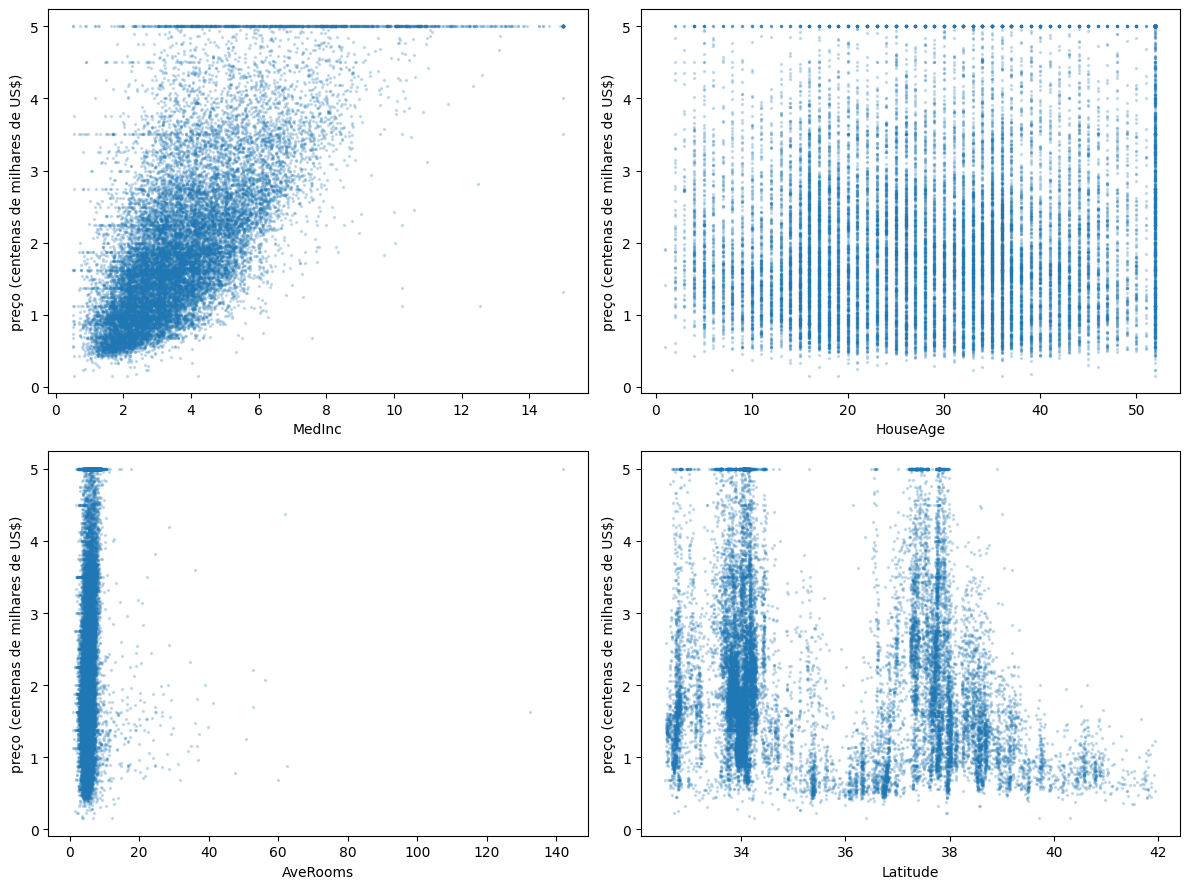

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
variaveis = ['MedInc', 'HouseAge', 'AveRooms', 'Latitude']

for ax, var in zip(axs.flat, variaveis):
    ax.scatter(df[var], df['MedHouseVal'], s=2, alpha=0.2)
    ax.set_xlabel(var)
    ax.set_ylabel('preço (centenas de milhares de US$)')

plt.tight_layout()
plt.show()

In [5]:
# correlação de cada variável com o preço
df.corr()['MedHouseVal'].sort_values(ascending=False).round(3)

,MedHouseVal
MedHouseVal,1.000
MedInc,0.688
AveRooms,0.152
HouseAge,0.106
AveOccup,-0.024
Population,-0.025
Longitude,-0.046
AveBedrms,-0.047
Latitude,-0.144


- MedInc é a variável que mais se relaciona com o preço, com correlação ~0.69: quanto maior a renda do bairro, mais caras as casas. Dá pra ver uma tendência linear no gráfico.
- HouseAge e AveRooms quase não têm relação linear com o preço sozinhas.
- Em Latitude aparecem dois "picos", que devem ser as regiões de Los Angeles com aprox. 34 e San Francisco com aprox. 37.5. Essa relação não é linear, então uma reta não vai pegar ela muito bem.
- Também aparece a linha horizontal em 5.0, com corte de $ 500 mil dólares.

### Treino × validação × teste (70/15/15)

Primeiro separo 30% dos dados, e depois divido esses 30% no meio entre validação e teste. O teste só vai ser usado no final, pra medir o erro do modelo.

In [6]:
x_raw = X.to_numpy()                  # (20640, 8)
y_raw = y.to_numpy().reshape(-1, 1)   # (20640, 1)

x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_raw, y_raw, test_size=0.3, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.5, random_state=42)

print('treino:   ', x_train_raw.shape)
print('validação:', x_val_raw.shape)
print('teste:    ', x_test_raw.shape)

treino:    (14448, 8)
validação: (3096, 8)
teste:     (3096, 8)


### Padronização

Igual no 2.6: o `StandardScaler` é ajustado (`fit`) só no treino e depois aplicado na validação e no teste, pra não vazar informação. O `x_scaler` padroniza cada uma das 8 colunas separadamente.

In [7]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()
x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()
x_test = torch.from_numpy(x_scaler.transform(x_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])


## Modelo

Agora são 8 entradas: `model.weight` tem shape (1, 8) e `model.bias` tem shape (1,).

In [8]:
model = nn.Linear(8, 1)
print('weight:', model.weight.shape)
print('bias:  ', model.bias.shape)

weight: torch.Size([1, 8])
bias:   torch.Size([1])


## Treinamento

Mesmas funções `train_epoch` e `validate_epoch` do 2.6.

In [9]:
lr = 0.1
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

In [10]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

In [11]:
n_epochs = 1000
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    val_loss = validate_epoch(model, criterion, x_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 100 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch[100/1000], Train Loss: 0.3938, Val Loss: 0.4066
Epoch[200/1000], Train Loss: 0.3908, Val Loss: 0.4039
Epoch[300/1000], Train Loss: 0.3907, Val Loss: 0.4038
Epoch[400/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[500/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[600/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[700/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[800/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[900/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[1000/1000], Train Loss: 0.3907, Val Loss: 0.4037


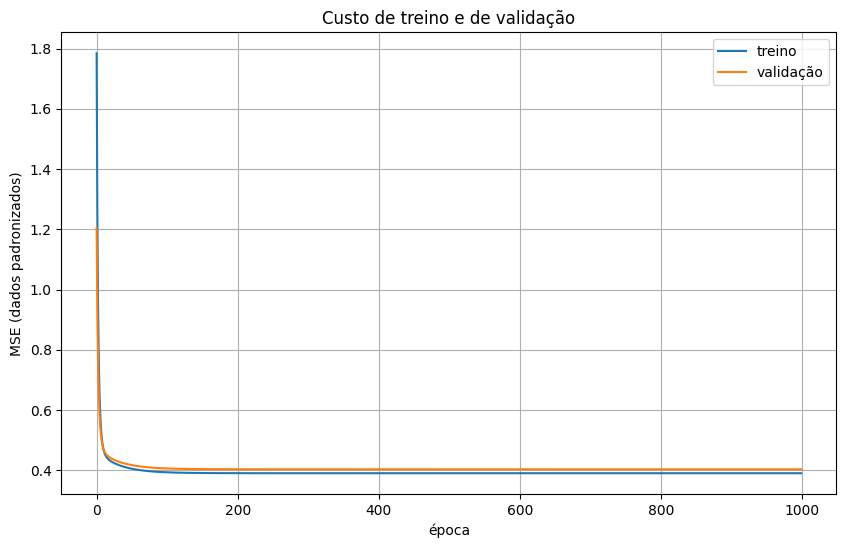

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='treino')
plt.plot(val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('MSE (dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

O custo cai rápido nas primeiras 100 épocas e depois estabiliza: treino em 0.391 e validação em 0.404. As duas curvas ficam bem próximas, então o modelo não está fazendo overfitting, o que faz sentido, já que são só 9 parâmetros pra mais de 14 mil amostras. Depois de umas 300 épocas não muda mais nada, ou seja, o gradiente descendente convergiu.

Conferi com o LinearRegression do scikit-learn e os pesos deram iguais aos do modelo treinado até a 3ª casa decimal.

## Avaliação no teste

Levo as previsões de volta pra escala original com `inverse_transform` e multiplico por 100.000 pra ficar em dólares. O baseline é um "modelo" que sempre prevê a média dos preços do treino.

In [13]:
model.eval()
with torch.no_grad():
    y_pred_test = model(x_test)

y_pred_test_raw = y_scaler.inverse_transform(y_pred_test.numpy())

rmse_test = np.sqrt(np.mean((y_pred_test_raw - y_test_raw) ** 2)) * 100_000

# baseline: sempre prevê a média do treino
media_treino = y_train_raw.mean()
rmse_baseline = np.sqrt(np.mean((media_treino - y_test_raw) ** 2)) * 100_000

print(f'RMSE do modelo no teste: US$ {rmse_test:,.0f}')
print(f'RMSE do baseline:        US$ {rmse_baseline:,.0f}')
print(f'preço médio no treino:   US$ {media_treino * 100_000:,.0f}')
print(f'redução do erro: {100 * (1 - rmse_test / rmse_baseline):.1f}%')

RMSE do modelo no teste: US$ 72,129
RMSE do baseline:        US$ 114,992
preço médio no treino:   US$ 206,924
redução do erro: 37.3%


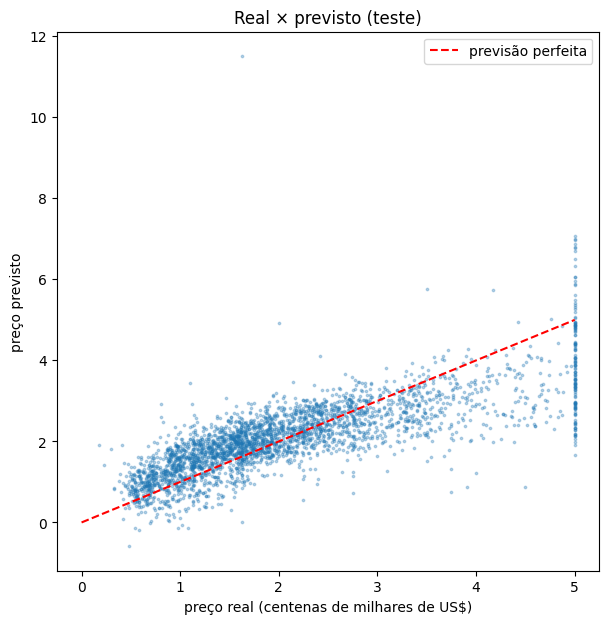

In [14]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test_raw, y_pred_test_raw, s=3, alpha=0.3)
plt.plot([0, 5], [0, 5], 'r--', label='previsão perfeita')
plt.xlabel('preço real (centenas de milhares de US$)')
plt.ylabel('preço previsto')
plt.title('Real × previsto (teste)')
plt.legend()
plt.show()

O modelo erra em média uns 72 mil dólares no teste, enquanto o baseline, 207 mil dólares, erra uns 115 mil dólares. Então o modelo reduz o erro em cerca de 37%, o que mostra que ele aprendeu alguma coisa útil.

No gráfico real VS previsto dá pra ver alguns problemas. Os pontos ficam espalhados em volta da linha vermelha, as casas de 500 mil dólares, que é o corte do dataset, aparecem como uma coluna vertical e o modelo subestima elas, e tem algumas previsões negativas ou acima de 5, que não fazem sentido. Também dá pra ver que o modelo tende a superestimar as casas baratas e subestimar as caras.

## Pesos aprendidos

In [15]:
pesos = pd.Series(model.weight.detach().numpy().ravel(), index=X.columns).sort_values()
print('bias:', model.bias.item())
pesos.round(3)

bias: 1.0254473714610413e-08


,0
Latitude,-0.772
Longitude,-0.750
AveRooms,-0.259
AveOccup,-0.036
Population,-0.001
HouseAge,0.106
AveBedrms,0.301
MedInc,0.734


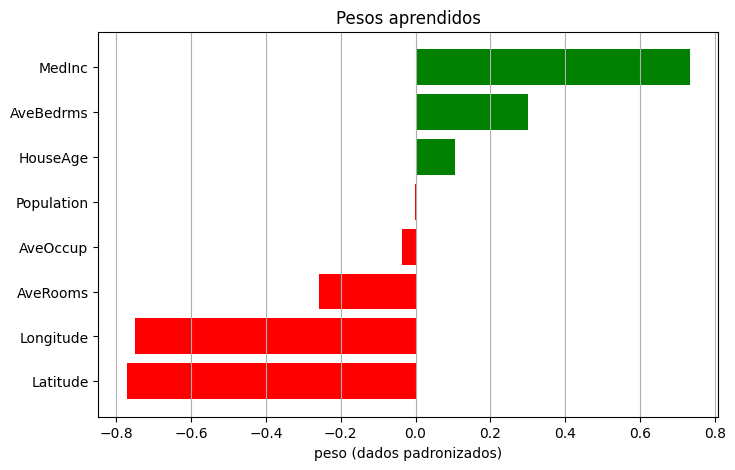

In [16]:
plt.figure(figsize=(8, 5))
cores = ['red' if p < 0 else 'green' for p in pesos]
plt.barh(pesos.index, pesos.values, color=cores)
plt.xlabel('peso (dados padronizados)')
plt.title('Pesos aprendidos')
plt.grid(True, axis='x')
plt.show()

Variáveis que mais aumentam o preço previsto: MedInc (+0.73) é de longe a mais importante, o que bate com a correlação que vi antes. Depois vem AveBedrms (+0.30) e HouseAge (+0.11).

Variáveis que mais diminuem o preço previsto: Latitude (-0.77) e Longitude (-0.75), seguidas de AveRooms (-0.26).

- Latitude e Longitude sozinhas têm correlação fraca com o preço, mas juntas elas indicam a localização. Os dois pesos negativos fazem o preço cair quando a gente vai pro norte e pro leste, ou seja, longe do litoral, onde as casas são mais baratas.
- AveRooms com peso negativo e AveBedrms com peso positivo parece estranho, mas as duas variáveis são muito correlacionadas entre si. O modelo meio que usa a diferença entre elas: com o mesmo número de quartos, ter mais cômodos aumenta o preço, mas como isso aparece dividido entre os dois pesos, não dá pra interpretar cada um sozinho.
- Population tem peso praticamente zero, então quase não influencia.

Por que só dá pra comparar os pesos porque as entradas foram padronizadas:o peso diz quanto o preço muda quando a variável aumenta 1 unidade. Sem padronizar, "1 unidade" de Population é 1 pessoa e "1 unidade" de MedInc é 10 mil dólares de renda, então um peso pequeno em Population poderia ter um efeito enorme só porque os valores dela são grandes. Com a padronização, todas as variáveis ficam com média 0 e desvio 1, então o peso passa a significar "quanto o preço muda quando a variável aumenta 1 desvio padrão", e aí dá pra comparar uma com a outra.

## Conclusão

O modelo é bem melhor que o baseline, com erro 37% menor, mas não acho que seja bom o suficiente pra prever preço de casa de verdade: um erro médio de 72 mil numa casa de $ 200 mil dólares. O principal problema é que ele é uma reta, e algumas relações não são lineares, principalmente a localização.

O que pode melhorar
- Rede neural com camadas escondidas e ativação não linear, pra conseguir pegar relações não lineares.
- Criar novas variáveis, como a distância até o litoral ou até LA/San Francisco, ou interações entre latitude e longitude.
- Tratar os outliers de AveRooms, AveBedrms e AveOccup, cortando ou aplicando log.
- Aplicar log no Population.
- Lidar com o corte em $ 500 mil, tirando essas amostras ou tratando elas.
